# Grant-proposal behavioural figures

One-off figures for the K99/R00 proposal, built on the tested `tmaze.analysis`
layer (ADR-0112) plus the new per-frame `tmaze.analysis.trajectories` helper
(ADR-0128 for the outbound window + VTE dwell, ADR-0130 for the peri-junction
velocity, ADR-0133 for the junction min-speed spatial band + the VTE-vs-accuracy
quartile panel). All logic lives in those modules; this notebook only configures,
calls, and plots.

**Panels produced here:**

- **Panels 1-2 - annotated overhead view (rig-GUI captures).** The live rig GUI's
  online tracking (ROI + trajectory tail + Kalman centroid, TRACKING confidence,
  current zone) and the full task-zone overlay with active-zone detection, embedded
  from captured screenshots in the resources repo so the set is self-contained.
- **Panel 3 - trajectories by cue.** ~20 consecutive trials at chance-level vs
  higher performance, coloured by cue identity (cue A = high tone = blue, cue B =
  low tone = green), over a configurable per-trial window (default = the whole
  trial, `trial_start -> trial_end`; switch `TRAJ_END_EVENT` to `choice_time_iso`
  for the cue->choice outbound run only). Expect intermixed colours at chance,
  cue-separated paths when performance is higher.
- **Panel 4 (VTE) - deliberation dwell.** Per-trial time in the central stem +
  junction (a vicarious-trial-and-error proxy), chance vs higher-performance
  block.
- **Panel 5 (VTE) - peri-junction velocity.** Speed vs signed distance-from-junction
  (junction-anchored profile, mean +/- SEM, chance vs higher) plus three deliberation
  scalars (junction min speed, slowing index, pause time) with a Mann-Whitney U.
  Junction min speed / pause are taken over a stem-axis band around `s = 0` (shaded on
  the profile), since the slowdown starts up-stem before the junction polygon.
- **Panel 6 (VTE) - deliberation vs accuracy.** Pools every trial across the included
  sessions, splits it into quartiles by each of the four VTE measures, and compares
  choice accuracy across quartiles (Wilson 95% CIs + Q1-vs-Q4 two-proportion z-test),
  shown raw and z-scored within session. Tests whether more deliberation predicts
  better choices.
- **Panel 7 - occupancy & speed heatmaps.** One row per rat (`HEATMAP_ANIMALS`):
  a mean-speed map (where each rat slows down; cool = slow) plus an occupancy map,
  pooling every frame in a configurable per-trial window (default trial start ->
  first well lick, with a trial-end fallback for no-lick trials). The 2D view of
  the Panel 5 profile - reveals whether a preferred slow-down zone is on the stem
  midline or off it (e.g. one arm entry).
- **Panel 8 - heatmaps over the rig image.** The same per-rat maps laid translucently
  on each rat's overhead background frame, one figure per rat, so the hot-spots sit on
  the real maze.
- **Panel 9 - low- vs high-accuracy block heatmaps.** The occupancy & mean-speed maps
  restricted to the selected rat's chance vs higher-performance block (a 2x2 grid, shared
  colour scales), to compare the slow-down pattern between a chance and a higher-accuracy
  run.
- **Optional** - a clean task-zone reference over the overhead view.

Default animal is **600** for the trajectory overlays; set `ANIMAL = "602"` and
re-run for the VTE-focused figure (602 deliberates more).

**Run:** `jupyter lab host/notebooks/grant_figures/proposal_figures.ipynb` from the
repo root in the `drieu_t_maze` env (after `pip install -e .`). Recordings are read
from `TMAZE_RECORDINGS_DIR` (default rig folder). Figures are written to `outputs/`.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from tmaze.analysis import bundle_reader, choice_signals
from tmaze.analysis import trajectories as tj
from tmaze.core import maze_state

# ----- configuration -------------------------------------------------------
ANIMAL = "600"          # 600 for the trajectory overlays; "602" for the VTE figure
START_DATE = "2026-08-26"
END_DATE = "2026-08-26"  # 8/26 bundles slot in automatically once recorded
BLOCK = 20               # trials per block window
BLOCK_STEP = 1        # block stride: None/BLOCK = non-overlapping tiling; 1 = 1-trial
                         # sliding window (select_blocks then picks the most-separated
                         # chance-vs-high pair that shares NO trials)
EXCLUDE_INTERVENTION = True  # drop windows overlapping a de-bias / de-alternation block
END_PAD_S = 0.6          # VTE panels (4-5): seconds past choice_time so a trace enters the arm
PAUSE_SPEED_CMS = 15 #tj.DEFAULT_PAUSE_SPEED_CMS  # Panel 5: "pause" speed threshold (cm/s)
SMOOTH_N = 3 #tj.DEFAULT_SMOOTH_N  # Panel 5: speed rolling-mean window (frames); 1 disables
# Panels 5-6: junction min-speed / pause are measured over a stem-axis band this many
# cm before / after the junction point (s_junction_cm = 0), NOT JUNCTION-zone membership
# (the dip starts up-stem; see the ADR superseding ADR-0130's region).
JUNCTION_BEFORE_CM = 72 #tj.DEFAULT_JUNCTION_BEFORE_CM  # 10 cm before s=0
JUNCTION_AFTER_CM = 0 #tj.DEFAULT_JUNCTION_AFTER_CM    # 5 cm after s=0
# Panel 6 (VTE vs accuracy quartiles): the per-trial deliberation measures to split on,
# as (column, label, more_vte_end) where more_vte_end says which quartile is MORE
# deliberative ("high" = Q4, "low" = Q1).
VTE_QUARTILE_MEASURES = [
    ("pause_time_s", "pause time (s)", "high"),
    ("dwell_s", "stem+junction dwell (s)", "high"),
    ("slowing_index", "slowing index", "high"),
    ("min_speed_cms", "junction min speed (cm/s)", "low"),
]
# Panel 7 (occupancy / speed heatmaps): one row per rat. Pools OUTBOUND-run frames
# across the date span; the mean-speed map shows where each rat slows (cool = slow).
HEATMAP_ANIMALS = ["600", "601", "602"]
HEATMAP_BINS = 55           # grid resolution over the normalized frame (bins per axis)
HEATMAP_MIN_COUNT = 3       # min frames in a bin to show a mean speed (else blank)
HEATMAP_SMOOTH_SIGMA = 1.0  # Gaussian smoothing in bins (0 = off; needs scipy)
# Per-trial window feeding the heatmaps (both maps), configurable like the Panel-3
# trajectories. Default = trial start -> the first well lick at trial end.
HEATMAP_START_EVENT = "trial_start_iso"
HEATMAP_END_EVENT = "lick_time_iso"          # first center-well lick after reward
HEATMAP_END_FALLBACK_EVENT = "trial_end_iso"  # for no-lick trials (incorrect); "" to drop them
HEATMAP_START_PAD_S = 0.0
HEATMAP_END_PAD_S = 0.0
HEATMAP_OVERLAY_ALPHA = 0.25  # Panel 8: heatmap translucency over the rig background
# Panel 9 (low- vs high-accuracy block heatmaps for the selected ANIMAL). A single
# ~BLOCK-trial block has far fewer frames than the pooled per-rat maps, so use a coarser
# grid + lower min-count so bins aren't mostly blank.
BLOCK_HEATMAP_BINS = 32
BLOCK_HEATMAP_MIN_COUNT = 2

# Panel 3 trajectory window: which per-trial ISO events bound each drawn path, plus
# pads (seconds; may be negative to pull an edge earlier). Available events:
# trial_start_iso, choice_cue_on_iso, choice_cue_off_iso, choice_time_iso,
# reward_cmd_iso, return_cue_on_iso, return_cue_off_iso, trial_end_iso, lick_time_iso.
# Default spans the WHOLE trial (start -> end). Use choice_time_iso for the
# cue->choice decision run only (the ADR-0128 window the VTE panels use).
TRAJ_START_EVENT = "trial_start_iso"
TRAJ_END_EVENT = "trial_end_iso"
TRAJ_START_PAD_S = 0.0
TRAJ_END_PAD_S = 0.0

# cue A = HIGH tone, cue B = LOW tone (tj.CUE_A / tj.CUE_B).
CUE_COLORS = {tj.CUE_A: "tab:red", tj.CUE_B: "tab:green"}
CUE_NAMES = {tj.CUE_A: "High tone: Go Left", tj.CUE_B: "Low tone: Go Right"}

# Optional manual overrides. Set to (session_id, first_trial) matching a row of the
# blocks table below to pin a block instead of the automatic low/high pick.
LOW_OVERRIDE = None
HIGH_OVERRIDE = None

# Zone outlines drawn on the overlays (the full figure-8 vocabulary).
ZONE_OUTLINES = (
    maze_state.HUB, maze_state.CENTRAL_STEM, maze_state.JUNCTION,
    maze_state.LEFT_CHOICE, maze_state.RIGHT_CHOICE,
    maze_state.LEFT_RETURN, maze_state.RIGHT_RETURN,
)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("animal", ANIMAL, "| dates", START_DATE, "->", END_DATE, "| block", BLOCK)

animal 600 | dates 2026-08-26 -> 2026-08-26 | block 20


## Panels 1-2 - annotated overhead view (rig-GUI captures)

The live rig GUI overlays the tracked rat (ROI outline + Kalman-smoothed centroid +
recent trajectory tail) and the task zones on the overhead camera image, printing
the live TRACKING confidence and the current zone. These are captured **screenshots**
(not regenerated here) pulled from the resources repo
(`research_question/aug26_grant-related/`), shown so the figure set is self-contained:

- **Panel 1** - online tracking: ROI, centroid, and the outbound trajectory tail.
- **Panel 2** - the same run with the full task-zone vocabulary drawn and the active
  zone detected (`LEFT_CHOICE` here).
- A clean **zone reference** over the empty maze.

The images are located via `tmaze`'s resources resolver, so set the
`OS_CODE_T_MAZE_RESOURCES` env var if your resources repo is not the default sibling
folder.

saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\gui_overview_panels.png


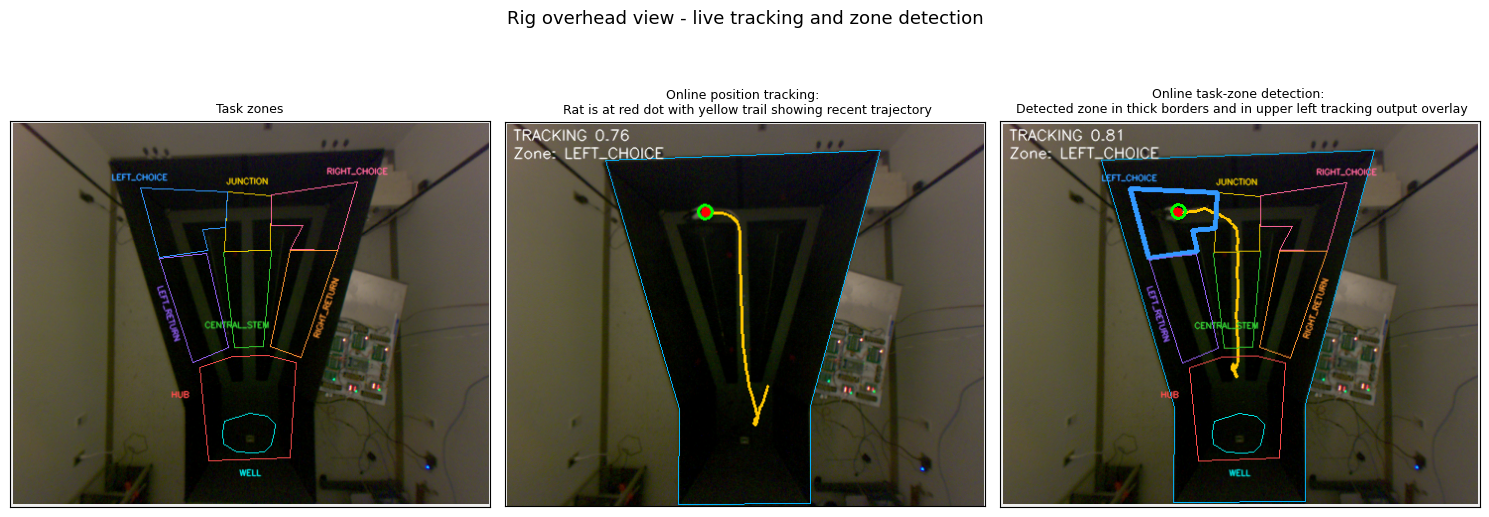

In [2]:
from tmaze.core.records.animals import resources_root

GUI_IMAGES_DIR = Path(resources_root()) / "research_question" / "aug26_grant-related"
gui_panels = [
    ("rig_zones.png", "Task zones"), 
    ("live_animal_tracking.png", "Online position tracking: \n Rat is at red dot with yellow trail showing recent trajectory"),
    ("live_animal_tracking_zone_detection.png", "Online task-zone detection: \n Detected zone in thick borders and in upper left tracking output overlay"),
]
present = [(GUI_IMAGES_DIR / fname, cap) for fname, cap in gui_panels
          if (GUI_IMAGES_DIR / fname).exists()]

if not present:
    print("No GUI capture images found under", GUI_IMAGES_DIR)
    print("Set OS_CODE_T_MAZE_RESOURCES if the resources repo lives elsewhere.")
else:
    fig, axes = plt.subplots(1, len(present), figsize=(5 * len(present), 6))
    axes = np.atleast_1d(axes)
    for ax, (path, cap) in zip(axes, present):
        ax.imshow(plt.imread(path))
        ax.set_title(cap, fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle("Rig overhead view - live tracking and zone detection", fontsize=13)
    fig.tight_layout()
    out = OUTPUT_DIR / "gui_overview_panels.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    print("saved", out.resolve())

## Load trials and pick the chance / higher-performance blocks

Load every bundle for the animal over the date span, derive per-trial signals
(`correct`, cue side, epoch), then cut each session into `BLOCK`-trial windows and
auto-pick the most-separated chance-vs-high pair. `BLOCK_STEP` sets the window
stride: the default (`None`) tiles into non-overlapping blocks; `BLOCK_STEP = 1`
slides one trial at a time, and `select_blocks` then returns the widest-gap pair
that shares **no** trials (so the two overlays — and the Panel 4/5 VTE stats —
stay independent). With `EXCLUDE_INTERVENTION = True` (default), any window that
overlaps a de-bias / de-alternation intervention block is dropped, so a block
reflects the animal's own free choices rather than a period when the task was
pushing a side. The table (sorted by accuracy) shows every window so you can pin
a different pair via `LOW_OVERRIDE` / `HIGH_OVERRIDE` above.

Note: on a stretch of late-training sessions the "low" block may sit above true
chance; the panel titles print the actual accuracy, so the figure stays honest.
Pull in an earlier session (widen `START_DATE`) if a genuine chance block is
wanted.

In [3]:
data = bundle_reader.load_animals((ANIMAL,), START_DATE, END_DATE)
signals = choice_signals.add_signals(data.trials)
print(f"{ANIMAL}: {len(data.sessions)} session(s), {len(signals)} trials")

blocks = tj.make_blocks(signals, block=BLOCK, step=BLOCK_STEP,
                        exclude_intervention=EXCLUDE_INTERVENTION)
blocks_df = pd.DataFrame([
    {"session_id": b.session_id, "first_trial": b.start_trial,
     "last_trial": b.end_trial, "accuracy": round(b.accuracy, 3),
     "cue_A": b.n_a, "cue_B": b.n_b}
    for b in blocks
])
print(f"{len(blocks)} block window(s) (block={BLOCK}, step={BLOCK_STEP or BLOCK})")
display(blocks_df.sort_values("accuracy").reset_index(drop=True))  # extremes at head/tail

def resolve_block(override, default):
    if override is None:
        return default
    sid, first = override
    for b in blocks:
        if b.session_id == sid and b.start_trial == first:
            return b
    raise ValueError(f"override {override!r} does not match any block above")

low_auto, high_auto = tj.select_blocks(signals, block=BLOCK, step=BLOCK_STEP,
                                       exclude_intervention=EXCLUDE_INTERVENTION)
low = resolve_block(LOW_OVERRIDE, low_auto)
high = resolve_block(HIGH_OVERRIDE, high_auto)
assert low is not None and high is not None, "no full block of BLOCK trials found"
print("LOW  ->", low.label)
print("HIGH ->", high.label)

600: 1 session(s), 90 trials
13 block window(s) (block=20, step=1)


,session_id,first_trial,last_trial,accuracy,cue_A,cue_B
0,600_20260826_132452,35,54,0.45,10,10
1,600_20260826_132452,36,55,0.45,11,9
2,600_20260826_132452,1,20,0.50,10,10
3,600_20260826_132452,66,85,0.60,10,10
4,600_20260826_132452,69,88,0.60,11,9
5,600_20260826_132452,71,90,0.60,12,8
6,600_20260826_132452,68,87,0.60,11,9
7,600_20260826_132452,65,84,0.65,11,9
8,600_20260826_132452,70,89,0.65,12,8
9,600_20260826_132452,67,86,0.65,10,10


LOW  -> 600_20260826_132452  trials 35-54  acc 45%  (A=10, B=10)
HIGH -> 600_20260826_132452  trials 63-82  acc 75%  (A=11, B=9)


## Panel 3 - trajectories coloured by cue

Each trace is one trial's path over a configurable per-trial window
`[TRAJ_START_EVENT + TRAJ_START_PAD_S, TRAJ_END_EVENT + TRAJ_END_PAD_S]` (set in the
config cell), drawn over the session's clean background frame with the task zones
outlined. Blue = cue A (high tone), green = cue B (low tone). Left = chance-level
block, right = higher-performance block.

The default spans the **whole trial** (`trial_start_iso -> trial_end_iso`), so the
outbound run *and* the reward/return leg are shown. For just the cue->choice
**outbound decision run** (the ADR-0128 window the VTE panels use), set
`TRAJ_END_EVENT = "choice_time_iso"` (optionally with `TRAJ_END_PAD_S = 0.6` so the
trace enters the chosen arm). Any of the events listed in the config cell can bound
either edge, and the pads (which may be negative) nudge the start/end.

In [4]:
def bundle_assets(block):
    """(bundle, sidecar, zone_map, background_image_or_None) for a block's session."""
    bundle = tj.find_bundle(block.session_id)
    sc = tj.load_sidecar(bundle)
    zm = tj.load_zone_map(bundle)
    bg_path = Path(bundle) / "video" / f"{block.session_id}_background.png"
    img = plt.imread(bg_path) if bg_path.exists() else None
    return bundle, sc, zm, img


def _frame_dims(sc, img):
    if img is not None:
        h, w = img.shape[:2]
        return int(w), int(h)
    return int(sc.width), int(sc.height)


def draw_zones(ax, zm, W, H):
    for z in zm.zones:
        if z.name not in ZONE_OUTLINES:
            continue
        xy = np.asarray(z.polygon, dtype=float)
        xs = np.append(xy[:, 0], xy[0, 0]) * W
        ys = np.append(xy[:, 1], xy[0, 1]) * H
        ax.plot(xs, ys, color="0.55", lw=1.0, alpha=0.8, zorder=1)


def plot_overlay(ax, block, title):
    _, sc, zm, img = bundle_assets(block)
    W, H = _frame_dims(sc, img)
    if img is not None:
        ax.imshow(img, cmap="gray", zorder=0)
    else:
        ax.set_xlim(0, W)
        ax.set_ylim(H, 0)
    draw_zones(ax, zm, W, H)

    win = tj.outbound_windows(
        block.trials, start_event=TRAJ_START_EVENT, end_event=TRAJ_END_EVENT,
        start_pad_s=TRAJ_START_PAD_S, end_pad_s=TRAJ_END_PAD_S)
    labelled = set()
    for _, r in win.iterrows():
        seg = tj.slice_xy(sc, r["t_start"], r["t_end"])
        if seg.empty:
            continue
        cue = r["cue"]
        ax.plot(seg["track_smooth_cx"], seg["track_smooth_cy"],
                color=CUE_COLORS.get(cue, "0.3"), lw=2.3, alpha=0.1, zorder=2,
                label=CUE_NAMES.get(cue) if cue not in labelled else None)
        labelled.add(cue)

    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")
    ax.legend(loc="lower right", fontsize=8, framealpha=0.9)

saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\trajectories_600.png


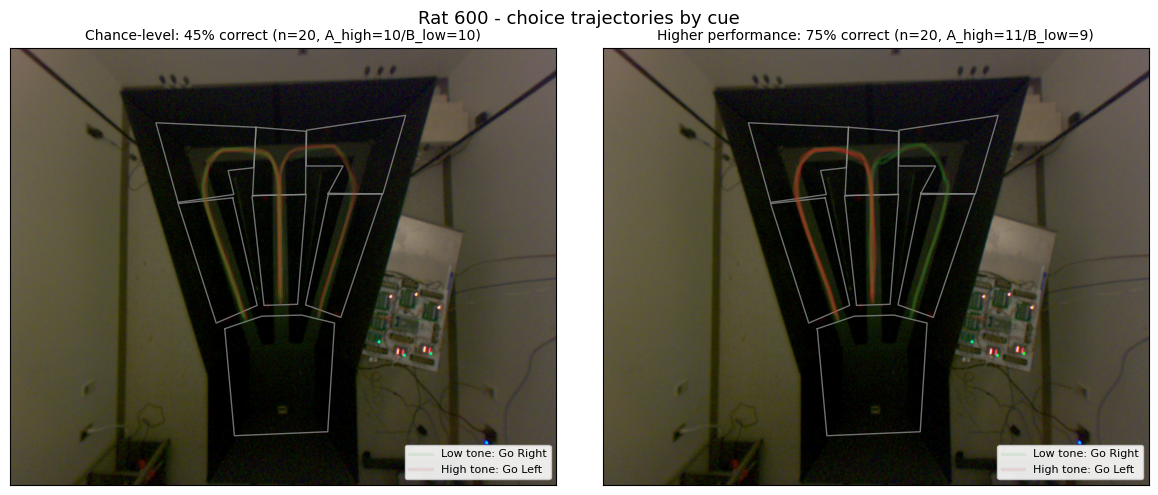

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_overlay(
    axes[0], low,
    f"Chance-level: {low.accuracy * 100:.0f}% correct "
    f"(n={low.n_a + low.n_b}, A_high={low.n_a}/B_low={low.n_b})",
)
plot_overlay(
    axes[1], high,
    f"Higher performance: {high.accuracy * 100:.0f}% correct "
    f"(n={high.n_a + high.n_b}, A_high={high.n_a}/B_low={high.n_b})",
)
fig.suptitle(f"Rat {ANIMAL} - choice trajectories by cue", fontsize=13)
fig.tight_layout()
out = OUTPUT_DIR / f"trajectories_{ANIMAL}.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
print("saved", out.resolve())

## Panel 4 (optional) - VTE deliberation dwell

Per-trial time the animal spends in the **central stem + junction** during the
outbound run - a simple vicarious-trial-and-error proxy (a pause at cue onset in
the stem, head-swinging at the choice point). Compared between the chance-level
and higher-performance blocks, with a SciPy-free Mann-Whitney U. Most informative
for rat 602 (set `ANIMAL = "602"` and re-run from the top).

saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\vte_dwell_600.png
  chance (45%): n=20  mean=0.86s  median=0.87s
  higher (75%): n=20  mean=0.94s  median=0.90s


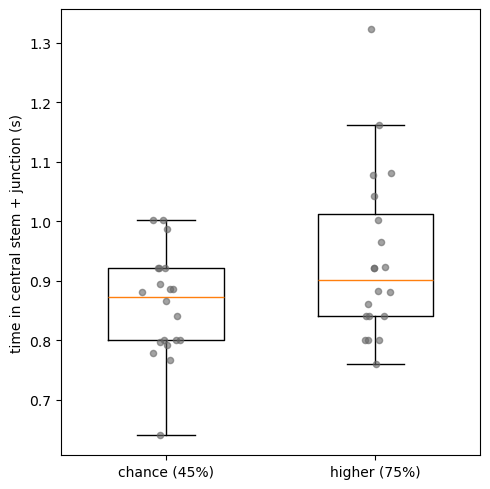

In [6]:
def dwell_for_block(block, group_label):
    """Per-trial VTE dwell for one block, tagged with a group label."""
    bundle = tj.find_bundle(block.session_id)
    sc = tj.load_sidecar(bundle)
    zm = tj.load_zone_map(bundle)
    win = tj.outbound_windows(block.trials, end_pad_s=END_PAD_S)
    dw = tj.dwell_per_trial(sc, zm, win)
    dw = dw[dw["n_samples"] > 0].copy()   # drop trials with no tracking in-window
    dw["group"] = group_label
    return dw

low_lbl = f"chance ({low.accuracy * 100:.0f}%)"
high_lbl = f"higher ({high.accuracy * 100:.0f}%)"
vte_low = dwell_for_block(low, low_lbl)
vte_high = dwell_for_block(high, high_lbl)

groups = [vte_low["dwell_s"].to_numpy(), vte_high["dwell_s"].to_numpy()]
labels = [low_lbl, high_lbl]
U, p = tj.mann_whitney_u(groups[0], groups[1])

fig, ax = plt.subplots(figsize=(5, 5))
ax.boxplot(groups, showfliers=False, widths=0.55)
rng = np.random.default_rng(0)
for i, g in enumerate(groups, start=1):
    ax.scatter(rng.normal(i, 0.05, len(g)), g, s=20, alpha=0.6, color="0.4", zorder=3)
ax.set_xticks([1, 2])
ax.set_xticklabels(labels)
ax.set_ylabel("time in central stem + junction (s)")
#ax.set_title(
#    f"Rat {ANIMAL} VTE dwell - Mann-Whitney U={U:.0f}, p={p:.3f}", fontsize=10
#)
fig.tight_layout()
out = OUTPUT_DIR / f"vte_dwell_{ANIMAL}.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
print("saved", out.resolve())
for lbl, g in zip(labels, groups):
    print(f"  {lbl}: n={len(g)}  mean={g.mean():.2f}s  median={np.median(g):.2f}s")

## Panel 5 (VTE) - peri-junction velocity

A junction-anchored **speed profile**: for each outbound trial we add per-frame
speed (cm/s, central-difference of the smoothed centroid x the bundle's
`cm_per_px`, then a centred rolling mean over `SMOOTH_N` frames - set `SMOOTH_N = 1`
in the config cell to disable that stage) and a signed distance along the stem axis
(`s_junction_cm`; 0 at the junction, negative down the stem). Pooling trials and
binning by distance gives a mean +/- SEM curve, chance vs higher block overlaid. The **cue zone** (`CENTRAL_STEM`, where the choice tone
plays while the rat climbs the stem - see `cue_gate.py` / ADR-0045) and the
`JUNCTION` extent are shaded, and `x = 0` (the junction) is marked. Rats usually
keep speed up through the stem and only dip at the junction on deliberative trials,
so a **deeper/wider dip near 0** is the VTE signature.

Then three **deliberation scalars** per trial (junction min speed, slowing index
`1 - min/peak`, and pause time below `PAUSE_SPEED_CMS`), chance vs higher, each with
a SciPy-free Mann-Whitney U. Junction **min speed** and **pause time** are measured
over the hatched **min-speed band** on the profile - a stem-axis window
`[-JUNCTION_BEFORE_CM, +JUNCTION_AFTER_CM]` cm around the junction point (`s = 0`),
NOT `JUNCTION`-polygon membership: the profile shows the dip starts up-stem and bottoms
out at/just before the border, so the band catches slowing the zone test would miss.
Definitions + the threshold value are pinned in ADR-0130 and the ADR superseding its
min-speed region. Most informative for rat 602 (`ANIMAL = "602"`, re-run from the top).

In [7]:
def _zone_band_cm(zm, name, axis, width, height, cm_per_px):
    """A zone polygon's (lo, hi) extent in cm along the stem axis (0 = junction).

    Used to shade where a zone sits on the peri-junction x-axis: the JUNCTION
    extent and the CUE ZONE (= CENTRAL_STEM, where the choice tone plays while the
    rat climbs the stem; see cue_gate.py / ADR-0045). Returns None if absent.
    """
    z = next((zz for zz in zm.zones if zz.name == name), None)
    if z is None or axis is None:
        return None
    (bx, by), (tx, ty) = axis
    bpx = np.array([bx * width, by * height])
    upx = np.array([tx * width, ty * height]) - bpx
    length_px = float(np.hypot(*upx))
    verts = np.asarray(z.polygon, dtype=float) * [width, height]
    along = ((verts[:, 0] - bpx[0]) * upx[0] + (verts[:, 1] - bpx[1]) * upx[1]) / length_px
    s = (along - length_px) * cm_per_px
    return (float(s.min()), float(s.max()))


def kin_for_block(block, group_label):
    """Per-trial peri-junction speed profiles + slowing/pause scalars for one block.

    Returns (profiles, kin_df, junction_band, cue_band): a list of per-trial
    (s_junction_cm, speed_cms) frames, the per-trial scalar table, and the JUNCTION
    and CUE-ZONE (CENTRAL_STEM) extents in cm along the stem axis (for the shaded
    bands).
    """
    bundle = tj.find_bundle(block.session_id)
    sc = tj.load_sidecar(bundle)
    zm = tj.load_zone_map(bundle)
    cm_per_px = tj.load_scale(bundle)
    axis = tj.stem_axis(zm)
    sc_k = tj.with_kinematics(sc, cm_per_px, axis, smooth_n=SMOOTH_N)  # adds speed_cms + s_junction_cm

    win = tj.outbound_windows(block.trials, end_pad_s=END_PAD_S)
    profiles = []
    for _, r in win.iterrows():
        prof = tj.peri_junction_profile(tj.slice_xy(sc_k, r["t_start"], r["t_end"]))
        if not prof.empty:
            profiles.append(prof)

    kin = tj.kinematics_per_trial(sc_k, zm, win, pause_speed_cms=PAUSE_SPEED_CMS,
                                  band_before_cm=JUNCTION_BEFORE_CM,
                                  band_after_cm=JUNCTION_AFTER_CM)
    kin = kin[kin["n_samples"] > 0].copy()                 # drop trials with no in-window tracking
    kin["group"] = group_label

    # Zone extents projected onto the stem axis -> shaded bands in the profile:
    # the JUNCTION (choice point) and the CUE ZONE (CENTRAL_STEM, tone-on region).
    jband = _zone_band_cm(zm, maze_state.JUNCTION, axis, sc.width, sc.height, cm_per_px)
    cueband = _zone_band_cm(zm, maze_state.CENTRAL_STEM, axis, sc.width, sc.height, cm_per_px)
    return profiles, kin, jband, cueband


prof_low, kin_low, jband_low, cueband_low = kin_for_block(low, low_lbl)
prof_high, kin_high, jband_high, cueband_high = kin_for_block(high, high_lbl)
print(f"peri-junction profiles: chance {len(prof_low)}, higher {len(prof_high)} trials")

peri-junction profiles: chance 20, higher 20 trials


saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\peri_junction_profile_600.png


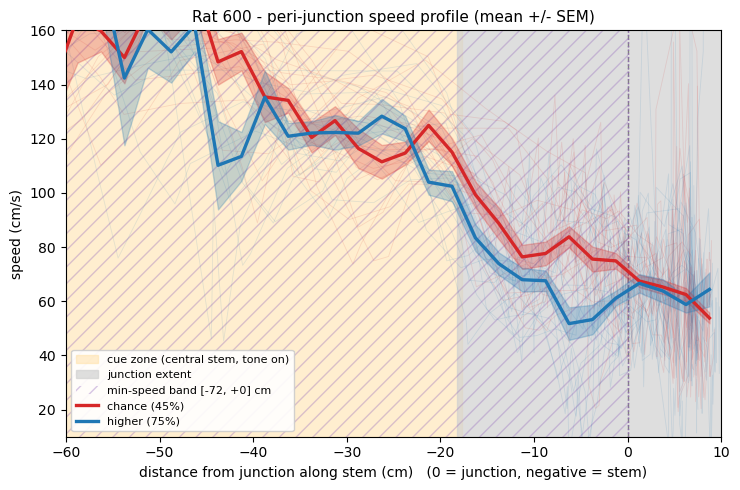

In [8]:
mp_low = tj.mean_profile(prof_low)
mp_high = tj.mean_profile(prof_high)

fig, ax = plt.subplots(figsize=(7.5, 5))

def _union_band(a, b):
    bands = [x for x in (a, b) if x is not None]
    return (min(x[0] for x in bands), max(x[1] for x in bands)) if bands else None

cue_band = _union_band(cueband_low, cueband_high)    # CENTRAL_STEM: choice tone ON
junc_band = _union_band(jband_low, jband_high)        # JUNCTION: the choice point
if cue_band is not None:
    ax.axvspan(*cue_band, color="#ffe1a8", alpha=0.55, zorder=0,
               label="cue zone (central stem, tone on)")
if junc_band is not None:
    ax.axvspan(*junc_band, color="0.82", alpha=0.7, zorder=0, label="junction extent")
ax.axvline(0.0, color="0.5", lw=1.0, ls="--", zorder=1)
# The spatial band over which junction min speed / pause are measured (10 cm before,
# 5 cm after s=0 by default) - hatched so it reads over the grey junction extent.
ax.axvspan(-JUNCTION_BEFORE_CM, JUNCTION_AFTER_CM, facecolor="none",
           edgecolor="tab:purple", hatch="//", linewidth=0.0, alpha=0.35, zorder=1,
           label=f"min-speed band [-{JUNCTION_BEFORE_CM:g}, +{JUNCTION_AFTER_CM:g}] cm")
for edge in (-JUNCTION_BEFORE_CM, JUNCTION_AFTER_CM):
    ax.axvline(edge, color="tab:purple", lw=1.0, ls=":", alpha=0.8, zorder=1)

for prof in prof_low:
    ax.plot(prof["s_junction_cm"], prof["speed_cms"], color="tab:red", lw=0.6,
            alpha=0.12, zorder=1)
for prof in prof_high:
    ax.plot(prof["s_junction_cm"], prof["speed_cms"], color="tab:blue", lw=0.6,
            alpha=0.12, zorder=1)
for mp, color, lbl in ((mp_low, "tab:red", low_lbl), (mp_high, "tab:blue", high_lbl)):
    if mp.empty:
        continue
    ax.plot(mp["s_cm"], mp["mean"], color=color, lw=2.4, zorder=3, label=lbl)
    ax.fill_between(mp["s_cm"], mp["mean"] - mp["sem"], mp["mean"] + mp["sem"],
                    color=color, alpha=0.25, zorder=2)

#ax.set_xlim(tj.PROFILE_S_MIN_CM, tj.PROFILE_S_MAX_CM)
ax.set_xlim(-60, tj.PROFILE_S_MAX_CM)
#ax.set_ylim(bottom=0)
ax.set_ylim(10, 160)
ax.set_xlabel("distance from junction along stem (cm)   (0 = junction, negative = stem)")
ax.set_ylabel("speed (cm/s)")
ax.set_title(f"Rat {ANIMAL} - peri-junction speed profile (mean +/- SEM)", fontsize=11)
ax.legend(loc="lower left", fontsize=8, framealpha=0.9)
fig.tight_layout()
out = OUTPUT_DIR / f"peri_junction_profile_{ANIMAL}.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
print("saved", out.resolve())

saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\peri_junction_metrics_600.png
  min_speed_cms: chance median=58.79 (n=20), higher median=39.90 (n=20)
  slowing_index: chance median=0.67 (n=20), higher median=0.80 (n=20)
  pause_time_s: chance median=0.00 (n=20), higher median=0.00 (n=20)


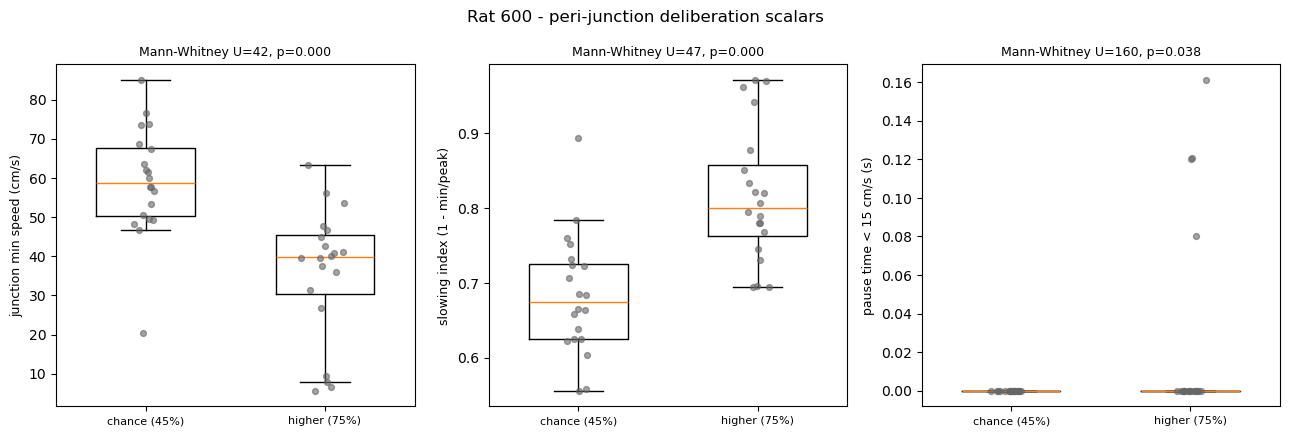

In [9]:
metric_specs = [
    ("min_speed_cms", "junction min speed (cm/s)"),
    ("slowing_index", "slowing index (1 - min/peak)"),
    ("pause_time_s", f"pause time < {PAUSE_SPEED_CMS:g} cm/s (s)"),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
rng = np.random.default_rng(1)
for ax, (col, ylabel) in zip(axes, metric_specs):
    g_low = kin_low[col].dropna().to_numpy()
    g_high = kin_high[col].dropna().to_numpy()
    U, p = tj.mann_whitney_u(g_low, g_high)
    ax.boxplot([g_low, g_high], showfliers=False, widths=0.55)
    for i, g in enumerate((g_low, g_high), start=1):
        ax.scatter(rng.normal(i, 0.05, len(g)), g, s=18, alpha=0.6, color="0.4", zorder=3)
    ax.set_xticks([1, 2])
    ax.set_xticklabels([low_lbl, high_lbl], fontsize=8)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_title(f"Mann-Whitney U={U:.0f}, p={p:.3f}", fontsize=9)

fig.suptitle(f"Rat {ANIMAL} - peri-junction deliberation scalars", fontsize=12)
fig.tight_layout()
out = OUTPUT_DIR / f"peri_junction_metrics_{ANIMAL}.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
print("saved", out.resolve())
for col, _ in metric_specs:
    lo = kin_low[col].dropna()
    hi = kin_high[col].dropna()
    print(f"  {col}: chance median={lo.median():.2f} (n={len(lo)}), "
          f"higher median={hi.median():.2f} (n={len(hi)})")

## Panel 6 (VTE) - does deliberation predict accuracy? (quartile split)

Instead of the two hand-picked blocks, this pools **every** completed trial across all
included sessions (dropping intervention trials when `EXCLUDE_INTERVENTION`), computes
the four per-trial deliberation measures over the outbound window (trial start ->
`choice_time + END_PAD_S`), splits the trials into **quartiles** by each measure, and
plots **choice accuracy per quartile** (Wilson 95% CIs, chance = 0.5) with a Q1-vs-Q4
**two-proportion z-test**. Junction min speed / pause use the `[-JUNCTION_BEFORE_CM,
+JUNCTION_AFTER_CM]` cm band (Panel 5). For `min_speed_cms` a **low** value is more VTE
(so Q1 is the high-deliberation end); for the others the high quartile is.

Two rows: **raw** pooled values, and values **z-scored within each session** first. The
raw row can be driven by across-day learning (early low-accuracy days may also differ in
VTE); the within-session row removes that between-session offset so the quartiles reflect
trial-by-trial deliberation. Drop policy is **per measure** - each panel uses every trial
where that measure is defined, so N can differ across panels (annotated on each). NaN
imputations: a pass-through with no slowing gets `slowing_index = 0` and
`min_speed_cms = peak_stem_speed_cms` (no dip) rather than being dropped. Definitions +
the quartile/stat choices are pinned in the ADR.

pooled 70 trials from 1 session(s)
saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\vte_accuracy_quartiles_600.png
  pause_time_s: Q1 acc=0.50 (n=18), Q4 acc=0.56 (n=18), p=0.738
  dwell_s: Q1 acc=0.61 (n=18), Q4 acc=0.61 (n=18), p=1.000
  slowing_index: Q1 acc=0.50 (n=18), Q4 acc=0.56 (n=18), p=0.738
  min_speed_cms: Q1 acc=0.56 (n=18), Q4 acc=0.50 (n=18), p=0.738


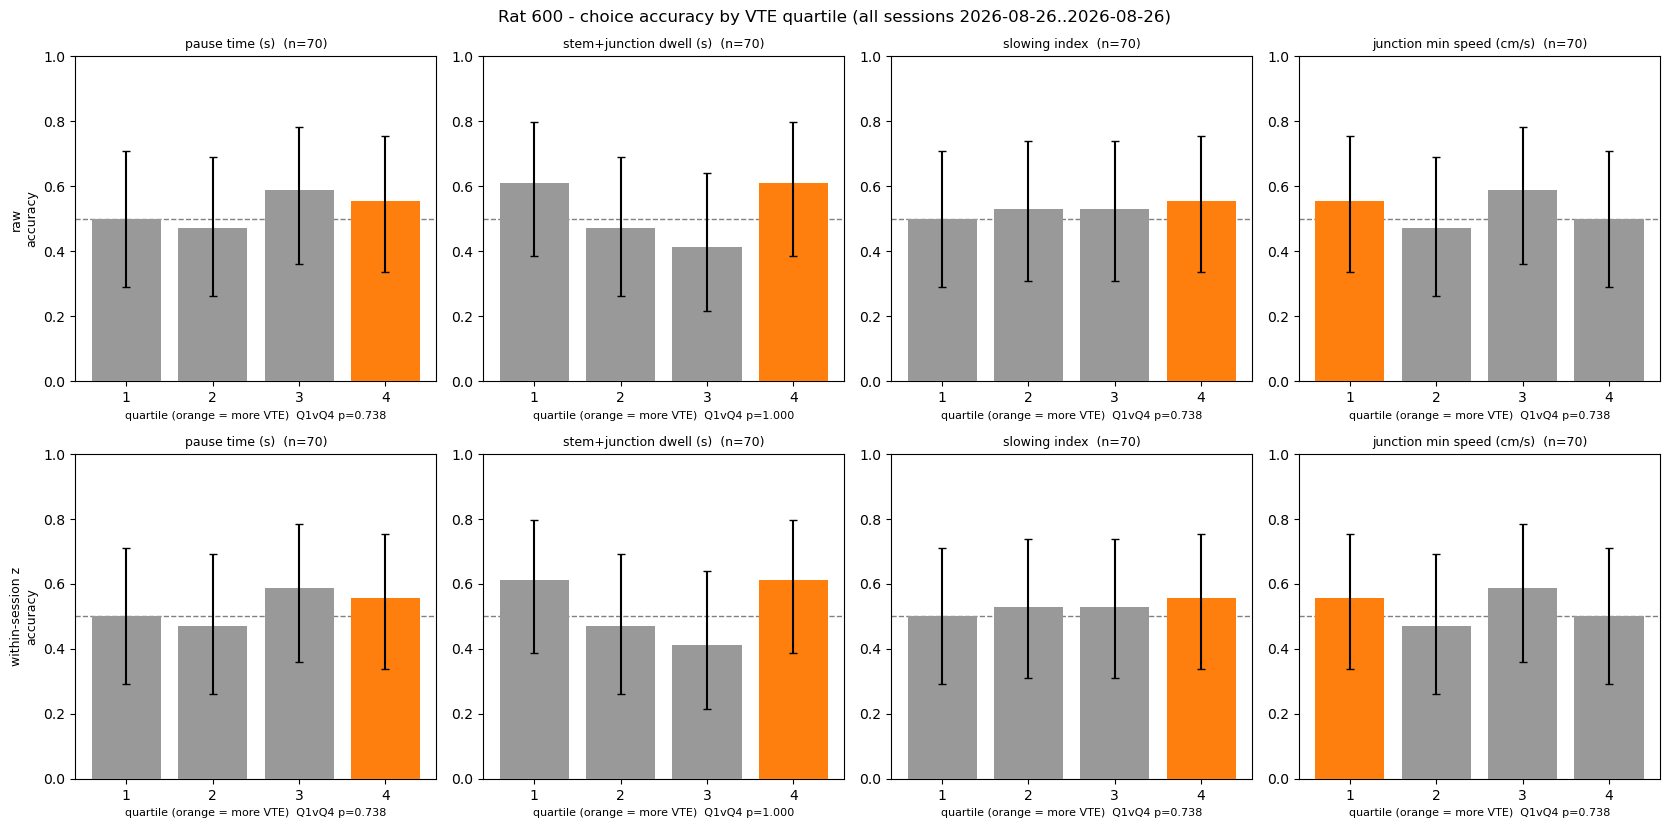

In [10]:
def vte_table_all_sessions(signals):
    """Per-trial VTE measures + correctness pooled over every session in the span.

    Loops sessions (one sidecar/zone-map/scale each), builds the outbound windows,
    runs the junction kinematics + VTE dwell, drops trials with no in-window tracking,
    and imputes the two "no-dip" NaNs. Honors EXCLUDE_INTERVENTION.
    """
    frames = []
    for sid, grp in signals.groupby("session_id", sort=False):
        bundle = tj.find_bundle(str(sid))
        if bundle is None:
            print(f"  skip {sid}: no bundle on disk")
            continue
        trials = grp
        if EXCLUDE_INTERVENTION and "in_block" in trials.columns:
            trials = trials[~trials["in_block"].astype("boolean").fillna(False)]
        if trials.empty:
            continue
        sc = tj.load_sidecar(bundle)
        zm = tj.load_zone_map(bundle)
        axis = tj.stem_axis(zm)
        cm_per_px = tj.load_scale(bundle)
        sc_k = tj.with_kinematics(sc, cm_per_px, axis, smooth_n=SMOOTH_N)
        win = tj.outbound_windows(trials, end_pad_s=END_PAD_S)
        if win.empty:
            continue
        kin = tj.kinematics_per_trial(sc_k, zm, win, pause_speed_cms=PAUSE_SPEED_CMS,
                                      band_before_cm=JUNCTION_BEFORE_CM,
                                      band_after_cm=JUNCTION_AFTER_CM)
        kin["dwell_s"] = tj.dwell_per_trial(sc_k, zm, win)["dwell_s"]
        kin = kin[kin["n_samples"] > 0].copy()
        # "No dip" imputations so pass-throughs stay in the low-VTE quartile instead
        # of being dropped: no slowing -> slowing_index 0; min speed -> stem peak.
        kin["slowing_index"] = kin["slowing_index"].fillna(0.0)
        kin["min_speed_cms"] = kin["min_speed_cms"].fillna(kin["peak_stem_speed_cms"])
        frames.append(kin)
    if not frames:
        return pd.DataFrame()
    vte = pd.concat(frames, ignore_index=True)
    for col, _lbl, _end in VTE_QUARTILE_MEASURES:
        vte[col + "_z"] = tj.zscore_by_group(vte, col, "session_id")
    return vte


vte_all = vte_table_all_sessions(signals)
n_sess = vte_all["session_id"].nunique() if not vte_all.empty else 0
print(f"pooled {len(vte_all)} trials from {n_sess} session(s)")

variants = [("", "raw"), ("_z", "within-session z")]
fig, axes = plt.subplots(len(variants), len(VTE_QUARTILE_MEASURES),
                         figsize=(4.2 * len(VTE_QUARTILE_MEASURES), 4.2 * len(variants)),
                         squeeze=False)
for r, (suffix, vlabel) in enumerate(variants):
    for c, (col, mlabel, more_vte_end) in enumerate(VTE_QUARTILE_MEASURES):
        ax = axes[r][c]
        qt = tj.accuracy_by_quartile(vte_all, col + suffix, q=4) \
            if not vte_all.empty else pd.DataFrame()
        if qt.empty:
            ax.text(0.5, 0.5, "insufficient data", ha="center", va="center",
                    transform=ax.transAxes, fontsize=9)
            ax.set_axis_off()
            continue
        acc = qt["accuracy"].to_numpy()
        yerr = np.vstack([acc - qt["ci_lo"].to_numpy(), qt["ci_hi"].to_numpy() - acc])
        hi_q = 4 if more_vte_end == "high" else 1     # the more-deliberative quartile
        colors = ["tab:orange" if q == hi_q else "0.6" for q in qt["quartile"]]
        ax.bar(qt["quartile"], acc, yerr=yerr, capsize=3, color=colors, zorder=3)
        ax.axhline(0.5, color="0.5", lw=1.0, ls="--", zorder=1)
        q1 = qt[qt["quartile"] == 1].iloc[0]
        q4 = qt[qt["quartile"] == 4].iloc[0]
        _z, p = tj.two_proportion_z(int(q1["n_correct"]), int(q1["n"]),
                                    int(q4["n_correct"]), int(q4["n"]))
        ax.set_ylim(0, 1)
        ax.set_xticks([1, 2, 3, 4])
        ax.set_xlabel(f"quartile (orange = more VTE)  Q1vQ4 p={p:.3f}", fontsize=8)
        if c == 0:
            ax.set_ylabel(f"{vlabel}\naccuracy", fontsize=9)
        ax.set_title(f"{mlabel}  (n={int(qt['n'].sum())})", fontsize=9)

fig.suptitle(f"Rat {ANIMAL} - choice accuracy by VTE quartile "
             f"(all sessions {START_DATE}..{END_DATE})", fontsize=12)
fig.tight_layout()
out = OUTPUT_DIR / f"vte_accuracy_quartiles_{ANIMAL}.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
print("saved", out.resolve())
for col, mlabel, more_vte_end in VTE_QUARTILE_MEASURES:
    qt = tj.accuracy_by_quartile(vte_all, col, q=4) if not vte_all.empty else pd.DataFrame()
    if qt.empty:
        continue
    q1 = qt[qt["quartile"] == 1].iloc[0]
    q4 = qt[qt["quartile"] == 4].iloc[0]
    _z, p = tj.two_proportion_z(int(q1["n_correct"]), int(q1["n"]),
                                int(q4["n_correct"]), int(q4["n"]))
    print(f"  {col}: Q1 acc={q1['accuracy']:.2f} (n={int(q1['n'])}), "
          f"Q4 acc={q4['accuracy']:.2f} (n={int(q4['n'])}), p={p:.3f}")

## Panel 7 - occupancy & speed heatmaps (where does each rat slow down?)

One row per rat (`HEATMAP_ANIMALS`). Pools every frame in a configurable per-trial
window (like the Panel-3 trajectories): `HEATMAP_START_EVENT -> HEATMAP_END_EVENT`
+ pads, default **trial start -> first well lick** (`lick_time_iso`). No-lick trials
(incorrect) fall back to `HEATMAP_END_FALLBACK_EVENT` (default `trial_end_iso`);
intervention trials are dropped when `EXCLUDE_INTERVENTION`. The same window feeds
both maps, which are binned over the normalized frame:

- **Mean-speed map** (left) - each bin coloured by the mean `speed_cms` of the frames
  in it (cool = slow). This is the "where does it decelerate" view - the 2D picture the
  Panel 5 stem-axis profile collapses to 1D, so it can reveal a preferred slow-down zone
  that isn't on the stem midline (e.g. asymmetric at one arm entry). Bins with fewer than
  `HEATMAP_MIN_COUNT` frames are left blank so a stray frame can't paint a fake slow spot.
- **Occupancy map** (right) - frame counts per bin (log scale), i.e. where the rat spends
  time. With the window running to the first lick, the reward well shows as a bright,
  slow hot-spot in both maps (expected); the deliberation signal is the slowing on the
  stem approaching the junction.

Zone outlines are overlaid (from each rat's most recent contributing session) and the
y-axis is flipped to the overhead-image orientation. `HEATMAP_SMOOTH_SIGMA` optionally
Gaussian-smooths the occupancy map (needs SciPy; skipped with a note if absent).
Independent of the single `ANIMAL` used by Panels 3-6. **Panel 8** re-uses this same
pooled data to lay the two maps translucently over each rat's rig background image.

saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\occupancy_speed_heatmaps.png


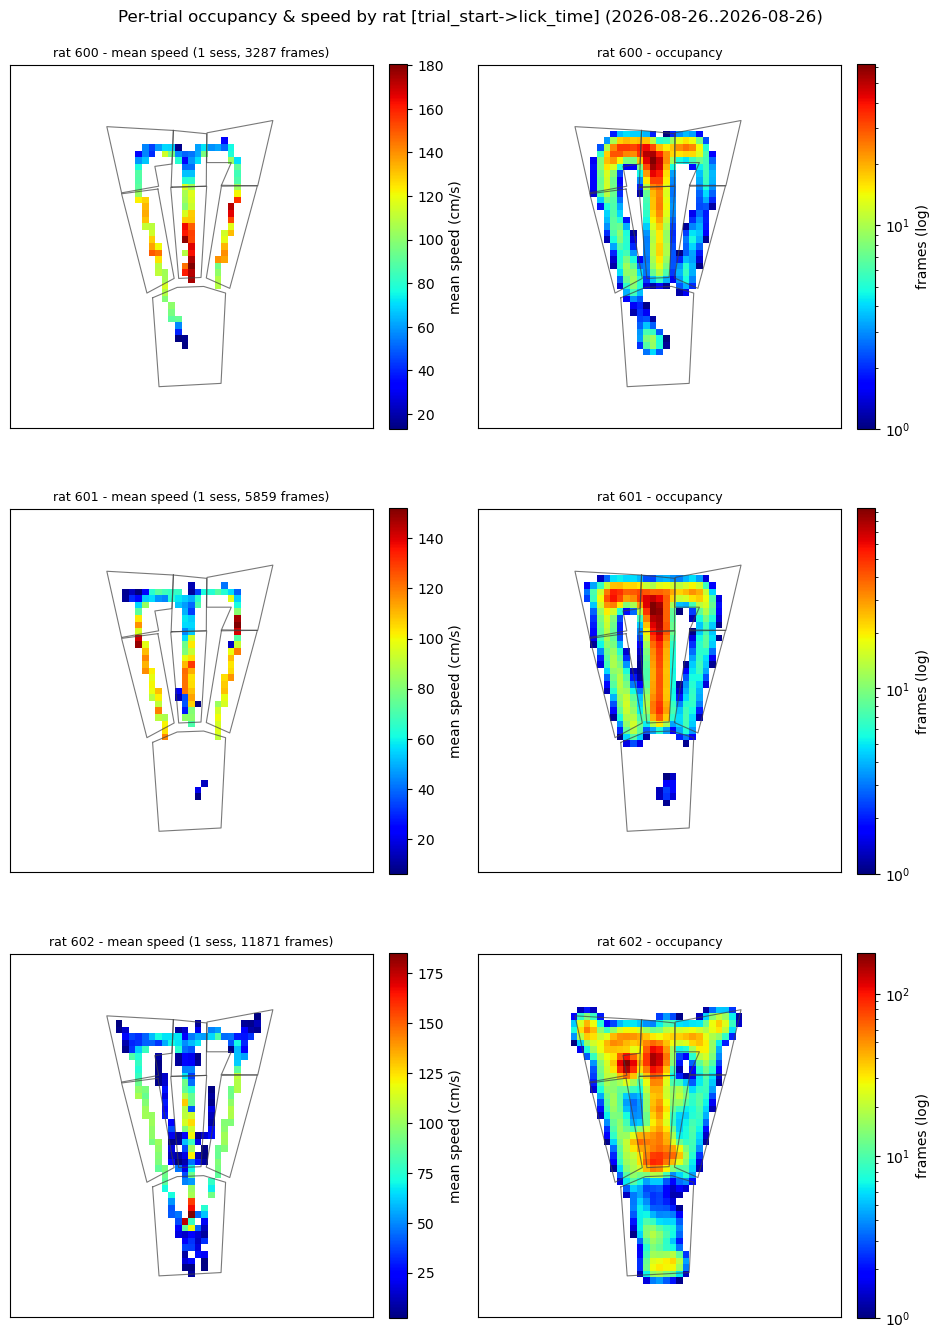

In [11]:
from matplotlib.colors import LogNorm

try:
    from scipy.ndimage import gaussian_filter as _gaussian_filter
except Exception:
    _gaussian_filter = None


def _hm_windows(trials):
    """outbound_windows for the HEATMAP_* per-trial window, shared by the per-rat and
    per-block panels. No-lick trials store HEATMAP_END_EVENT as an EMPTY STRING (not
    NaN), so coalesce onto HEATMAP_END_FALLBACK_EVENT on a non-blank test - else they'd
    parse to NaT, drop, and bias the maps toward rewarded trials.
    """
    trials = trials.copy()
    end_use = HEATMAP_END_EVENT
    fb = HEATMAP_END_FALLBACK_EVENT
    if HEATMAP_END_EVENT in trials.columns and fb and fb in trials.columns:
        end_s = trials[HEATMAP_END_EVENT].astype("string")
        has_end = end_s.notna() & (end_s.str.strip() != "")
        trials["_hm_end_iso"] = end_s.where(has_end, trials[fb])
        end_use = "_hm_end_iso"
    elif HEATMAP_END_EVENT not in trials.columns and fb in trials.columns:
        end_use = fb
    return tj.outbound_windows(
        trials, start_event=HEATMAP_START_EVENT, end_event=end_use,
        start_pad_s=HEATMAP_START_PAD_S, end_pad_s=HEATMAP_END_PAD_S)


def _pool_frames(sc_k, win):
    """Pooled (cx_n, cy_n, speed_cms) over all window rows of a kinematics sidecar."""
    xs, ys, sp = [], [], []
    for _, r in win.iterrows():
        seg = tj.slice_xy(sc_k, r["t_start"], r["t_end"])
        if seg.empty:
            continue
        xs.append(seg["cx_n"].to_numpy())
        ys.append(seg["cy_n"].to_numpy())
        sp.append(seg["speed_cms"].to_numpy())
    if not xs:
        return None
    return np.concatenate(xs), np.concatenate(ys), np.concatenate(sp)


_HEATMAP_CACHE = {}


def get_heatmap_frames(animal):
    """Pooled per-trial (cx_n, cy_n, speed_cms) for one rat, over the HEATMAP_* window.

    The window (both maps) runs HEATMAP_START_EVENT -> HEATMAP_END_EVENT + pads, per
    trial (default trial start -> first well lick). Trials with no HEATMAP_END_EVENT
    stamp (e.g. no-lick / incorrect) fall back to HEATMAP_END_FALLBACK_EVENT when set,
    else are dropped. Returns a dict (cx/cy/speed/zm/bundle/wh/n_sess) - the last
    session that contributed frames supplies the zone map + background - or None.
    Cached so Panels 7 and 8 don't reload the sessions twice.
    """
    if animal in _HEATMAP_CACHE:
        return _HEATMAP_CACHE[animal]
    d = bundle_reader.load_animals((animal,), START_DATE, END_DATE)
    sig = choice_signals.add_signals(d.trials)
    xs, ys, sp = [], [], []
    zm_last = bundle_last = wh_last = sid_last = None
    n_sess = 0
    for sid, grp in sig.groupby("session_id", sort=False):
        bundle = tj.find_bundle(str(sid))
        if bundle is None:
            continue
        trials = grp
        if EXCLUDE_INTERVENTION and "in_block" in trials.columns:
            trials = trials[~trials["in_block"].astype("boolean").fillna(False)]
        if trials.empty:
            continue
        sc = tj.load_sidecar(bundle)
        zm = tj.load_zone_map(bundle)
        axis = tj.stem_axis(zm)
        sc_k = tj.with_kinematics(sc, tj.load_scale(bundle), axis, smooth_n=SMOOTH_N)
        pooled = _pool_frames(sc_k, _hm_windows(trials))
        if pooled is not None:
            xs.append(pooled[0])
            ys.append(pooled[1])
            sp.append(pooled[2])
            zm_last, bundle_last, wh_last, sid_last = zm, bundle, (sc.width, sc.height), str(sid)
            n_sess += 1
    data = None if not xs else {
        "cx": np.concatenate(xs), "cy": np.concatenate(ys), "speed": np.concatenate(sp),
        "zm": zm_last, "bundle": bundle_last, "wh": wh_last, "sid": sid_last, "n_sess": n_sess}
    _HEATMAP_CACHE[animal] = data
    return data


def _draw_zones(ax, zm):
    for name in ZONE_OUTLINES:
        z = next((zz for zz in zm.zones if zz.name == name), None)
        if z is None:
            continue
        poly = np.asarray(list(z.polygon) + [z.polygon[0]], dtype=float)
        ax.plot(poly[:, 0], poly[:, 1], color="0.25", lw=0.8, alpha=0.7, zorder=5)


def _smooth(grid):
    if HEATMAP_SMOOTH_SIGMA and _gaussian_filter is not None:
        return _gaussian_filter(grid, HEATMAP_SMOOTH_SIGMA)
    return grid


rats = [a for a in HEATMAP_ANIMALS]
fig, axes = plt.subplots(len(rats), 2, figsize=(9.5, 4.6 * len(rats)), squeeze=False)
if HEATMAP_SMOOTH_SIGMA and _gaussian_filter is None:
    print("note: scipy not available - HEATMAP_SMOOTH_SIGMA ignored (raw bins shown)")
for row, animal in enumerate(rats):
    ax_sp, ax_occ = axes[row][0], axes[row][1]
    data = get_heatmap_frames(animal)
    if data is None:
        for ax in (ax_sp, ax_occ):
            ax.text(0.5, 0.5, f"rat {animal}: no data", ha="center", va="center",
                    transform=ax.transAxes)
            ax.set_axis_off()
        continue
    cx, cy, speed, zm, n_sess = data["cx"], data["cy"], data["speed"], data["zm"], data["n_sess"]
    occ, mean_sp, xe, ye = tj.speed_occupancy_grid(
        cx, cy, speed, bins=HEATMAP_BINS, min_count=HEATMAP_MIN_COUNT)
    # Mean speed (cool = slow); NaN bins stay blank. Not smoothed - a Gaussian would
    # bleed NaNs across the sparse edges of the outbound path.
    msp = np.ma.masked_invalid(mean_sp).T
    im0 = ax_sp.pcolormesh(xe, ye, msp, cmap="jet", shading="flat")
    fig.colorbar(im0, ax=ax_sp, fraction=0.046, pad=0.04, label="mean speed (cm/s)")
    ax_sp.set_title(f"rat {animal} - mean speed ({n_sess} sess, {len(cx)} frames)",
                    fontsize=9)
    # Occupancy (log counts); smoothed for readability if scipy is present.
    occ_s = _smooth(occ)
    occ_m = np.ma.masked_less(occ_s.T, 1.0)   # hide the <1-frame smoothing skirt
    im1 = ax_occ.pcolormesh(xe, ye, occ_m, cmap="jet",
                            norm=LogNorm(vmin=1.0, vmax=occ_m.max())
                            if occ_m.count() else None)
    fig.colorbar(im1, ax=ax_occ, fraction=0.046, pad=0.04, label="frames (log)")
    ax_occ.set_title(f"rat {animal} - occupancy", fontsize=9)
    for ax in (ax_sp, ax_occ):
        _draw_zones(ax, zm)
        ax.set_xlim(0, 1)
        ax.set_ylim(1, 0)          # flip to overhead-image orientation (cy_n=0 at top)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])

_win_lbl = f"{HEATMAP_START_EVENT.replace('_iso','')}->{HEATMAP_END_EVENT.replace('_iso','')}"
fig.suptitle(f"Per-trial occupancy & speed by rat [{_win_lbl}] ({START_DATE}..{END_DATE})",
             fontsize=12)
fig.tight_layout()
out = OUTPUT_DIR / "occupancy_speed_heatmaps.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
print("saved", out.resolve())

## Panel 8 - heatmaps overlaid on the rig image (per rat)

The same pooled per-trial data as Panel 7, but each map laid **translucently over that
rat's overhead background frame** so the slow-down/occupancy hot-spots sit on the real
maze. One figure per rat (`heatmap_overlay_<animal>.png`), two panels each: mean speed
(left) and occupancy (right). `HEATMAP_OVERLAY_ALPHA` sets the translucency.

The background is the clean frame from the rat's most recent contributing session
(`<session>_background.png`, the same image Panel 3 draws on); pooled frames span several
sessions, so the overlay assumes the maze didn't move between them (same approximation as
the zone outlines). If a background image is missing, the map is drawn on a blank canvas.

saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\heatmap_overlay_600.png
saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\heatmap_overlay_601.png
saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\heatmap_overlay_602.png


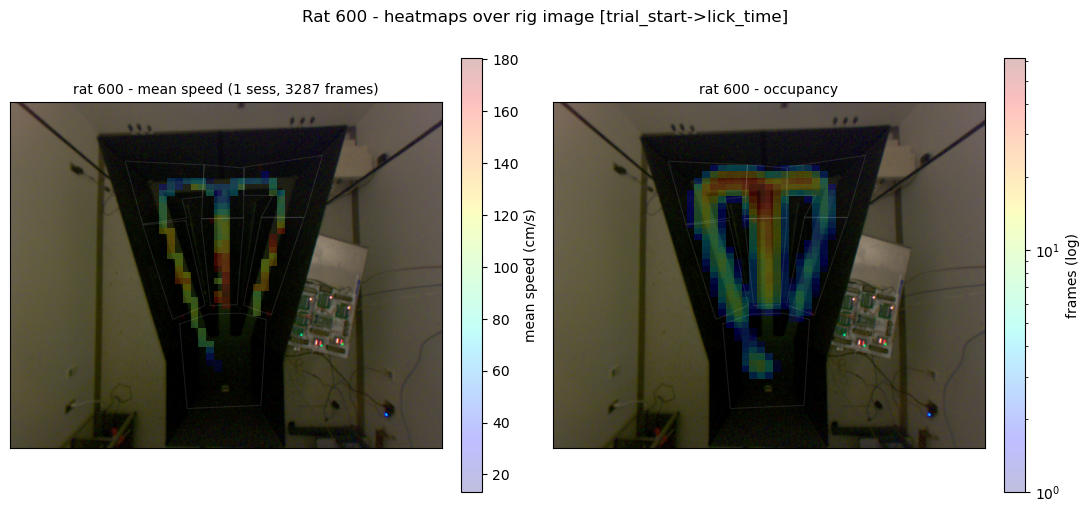

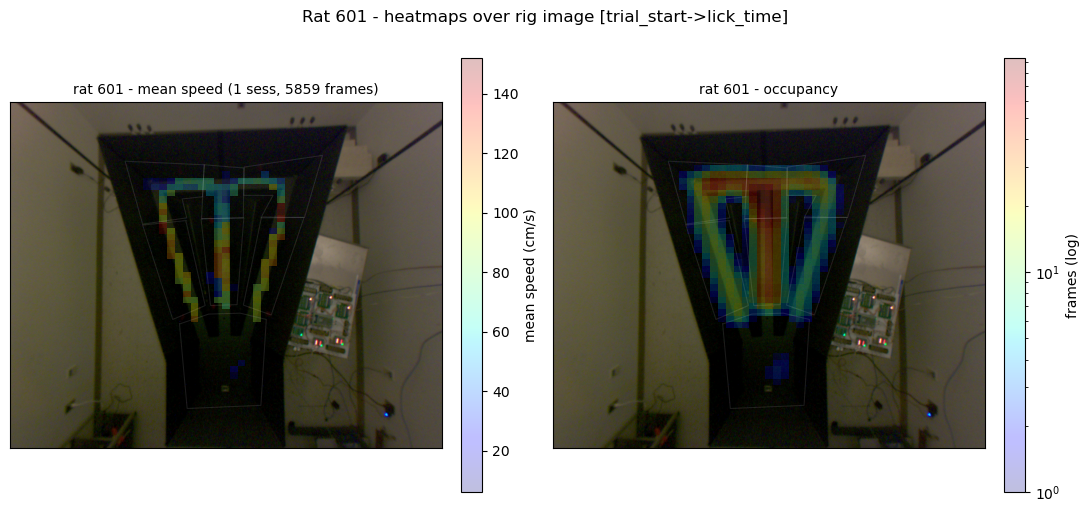

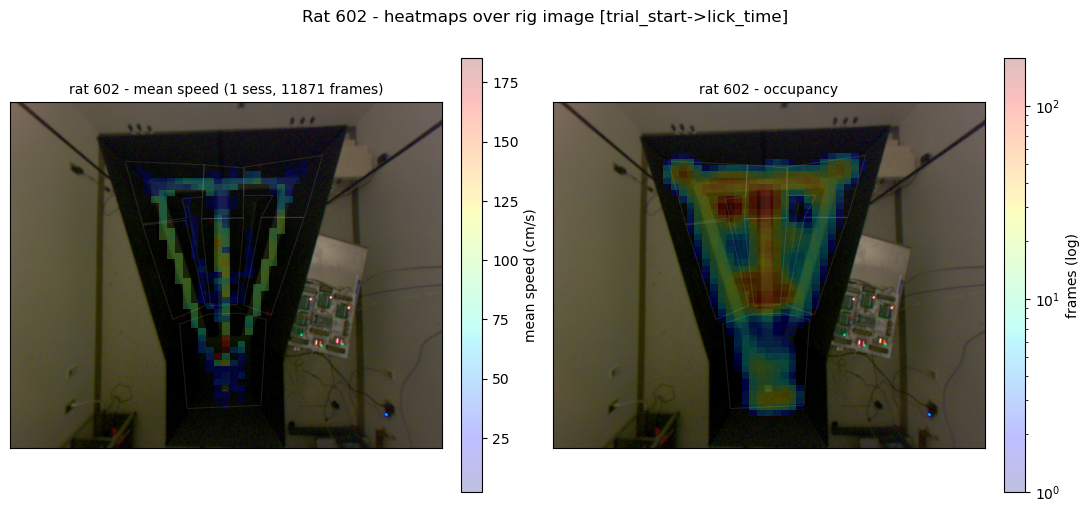

In [12]:
def _rig_background(data):
    """The rig background image + (W, H) for a rat's representative session, or (None, wh)."""
    wh = data.get("wh")
    bundle, sid = data.get("bundle"), data.get("sid")
    if bundle and sid:
        bg_path = Path(bundle) / "video" / f"{sid}_background.png"
        if bg_path.exists():
            img = plt.imread(bg_path)
            h, w = img.shape[0], img.shape[1]
            return img, (w, h)
    return None, wh


def _overlay_map(ax, img, wh, xe, ye, grid_masked, *, cmap, norm=None, label):
    """Draw the rig image (or blank) with a translucent heatmap in PIXEL coordinates."""
    w, h = wh
    if img is not None:
        ax.imshow(img, cmap="gray", extent=[0, w, h, 0], zorder=0)
    mesh = ax.pcolormesh(xe * w, ye * h, grid_masked, cmap=cmap, norm=norm,
                         alpha=HEATMAP_OVERLAY_ALPHA, shading="flat", zorder=1)
    plt.colorbar(mesh, ax=ax, fraction=0.046, pad=0.04, label=label)
    ax.set_xlim(0, w)
    ax.set_ylim(h, 0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


for animal in HEATMAP_ANIMALS:
    data = get_heatmap_frames(animal)
    fig, (ax_sp, ax_occ) = plt.subplots(1, 2, figsize=(11, 5.2))
    if data is None:
        for ax in (ax_sp, ax_occ):
            ax.text(0.5, 0.5, f"rat {animal}: no data", ha="center", va="center",
                    transform=ax.transAxes)
            ax.set_axis_off()
        plt.close(fig)
        continue
    occ, mean_sp, xe, ye = tj.speed_occupancy_grid(
        data["cx"], data["cy"], data["speed"], bins=HEATMAP_BINS, min_count=HEATMAP_MIN_COUNT)
    img, wh = _rig_background(data)
    if wh is None:      # no background and no known frame size -> unit square
        wh = (1.0, 1.0)
    # Mean speed (unsmoothed; NaN bins transparent so the rig shows through).
    _overlay_map(ax_sp, img, wh, xe, ye, np.ma.masked_invalid(mean_sp).T,
                 cmap="jet", label="mean speed (cm/s)")
    ax_sp.set_title(f"rat {animal} - mean speed ({data['n_sess']} sess, {len(data['cx'])} frames)",
                    fontsize=10)
    # Occupancy (log counts; optional smoothing).
    occ_m = np.ma.masked_less(_smooth(occ).T, 1.0)
    _overlay_map(ax_occ, img, wh, xe, ye, occ_m, cmap="jet",
                 norm=LogNorm(vmin=1.0, vmax=occ_m.max()) if occ_m.count() else None,
                 label="frames (log)")
    ax_occ.set_title(f"rat {animal} - occupancy", fontsize=10)
    # Zone outlines in pixel coords over both panels.
    w, h = wh
    for ax in (ax_sp, ax_occ):
        for name in ZONE_OUTLINES:
            z = next((zz for zz in data["zm"].zones if zz.name == name), None)
            if z is None:
                continue
            poly = np.asarray(list(z.polygon) + [z.polygon[0]], dtype=float)
            ax.plot(poly[:, 0] * w, poly[:, 1] * h, color="w", lw=0.8, alpha=0.1, zorder=6)
    _win_lbl = f"{HEATMAP_START_EVENT.replace('_iso','')}->{HEATMAP_END_EVENT.replace('_iso','')}"
    fig.suptitle(f"Rat {animal} - heatmaps over rig image [{_win_lbl}]", fontsize=12)
    fig.tight_layout()
    out = OUTPUT_DIR / f"heatmap_overlay_{animal}.png"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    print("saved", out.resolve())

## Panel 9 - low- vs high-accuracy block heatmaps (selected rat)

The same occupancy & mean-speed maps as Panel 7, but restricted to the two blocks the
figure contrasts for the **selected `ANIMAL`**: the chance-level (`low`) and higher-
performance (`high`) blocks picked in the block-selection cell. A 2x2 grid - rows = the
two blocks, columns = mean speed (cool = slow) and occupancy - lets you see whether the
rat's slow-down pattern differs between a chance and a higher-accuracy run.

Uses the same per-trial `HEATMAP_*` window (default trial start -> first well lick), but a
single ~`BLOCK`-trial block has far fewer frames than the pooled per-rat maps, so it uses
the coarser `BLOCK_HEATMAP_BINS` / `BLOCK_HEATMAP_MIN_COUNT`. Both blocks share one colour
scale per map so the two are directly comparable; drawn in the normalized frame with zone
outlines (like Panel 7), not on the rig image.

saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\block_heatmaps_600.png


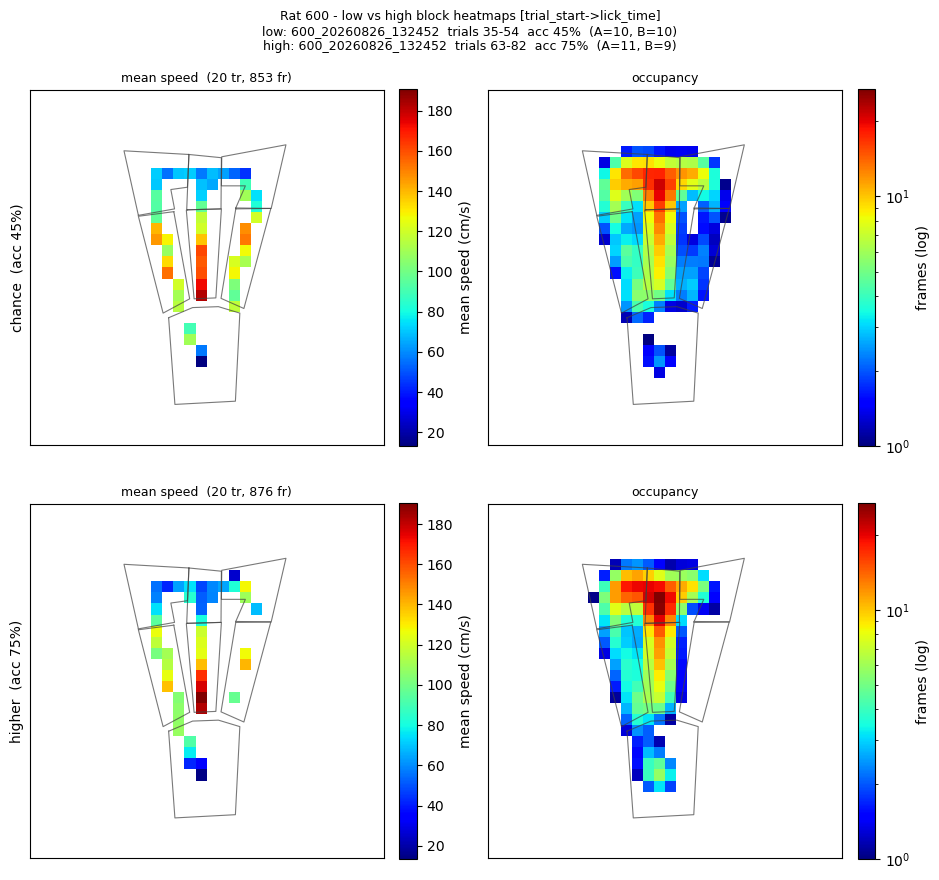

In [13]:
def block_heatmap(block):
    """Occupancy + mean-speed grids for a single block, over the HEATMAP_* window."""
    bundle, sc, zm, _img = bundle_assets(block)
    axis = tj.stem_axis(zm)
    sc_k = tj.with_kinematics(sc, tj.load_scale(bundle), axis, smooth_n=SMOOTH_N)
    pooled = _pool_frames(sc_k, _hm_windows(block.trials))
    if pooled is None:
        return None
    cx, cy, speed = pooled
    occ, mean_sp, xe, ye = tj.speed_occupancy_grid(
        cx, cy, speed, bins=BLOCK_HEATMAP_BINS, min_count=BLOCK_HEATMAP_MIN_COUNT)
    return {"occ": occ, "mean_sp": mean_sp, "xe": xe, "ye": ye, "zm": zm,
            "n_frames": len(cx), "n_trials": len(block.trials)}


computed = [("chance", low, block_heatmap(low)), ("higher", high, block_heatmap(high))]
dicts = [d for _, _, d in computed if d is not None]
# Shared colour scales across both blocks so the two are directly comparable.
_sp = np.concatenate([d["mean_sp"][np.isfinite(d["mean_sp"])].ravel() for d in dicts]) \
    if dicts else np.array([])
sp_vmin = float(_sp.min()) if _sp.size else 0.0
sp_vmax = float(_sp.max()) if _sp.size else 1.0
occ_vmax = max([float(_smooth(d["occ"]).max()) for d in dicts] + [1.0])

fig, axes = plt.subplots(2, 2, figsize=(9.5, 9), squeeze=False)
for row, (lbl, blk, d) in enumerate(computed):
    ax_sp, ax_occ = axes[row]
    if d is None:
        for ax in (ax_sp, ax_occ):
            ax.text(0.5, 0.5, f"{lbl}: no frames in window", ha="center", va="center",
                    transform=ax.transAxes)
            ax.set_axis_off()
        continue
    im0 = ax_sp.pcolormesh(d["xe"], d["ye"], np.ma.masked_invalid(d["mean_sp"]).T,
                           cmap="jet", vmin=sp_vmin, vmax=sp_vmax, shading="flat")
    fig.colorbar(im0, ax=ax_sp, fraction=0.046, pad=0.04, label="mean speed (cm/s)")
    ax_sp.set_ylabel(f"{lbl}  (acc {blk.accuracy * 100:.0f}%)", fontsize=10)
    ax_sp.set_title(f"mean speed  ({d['n_trials']} tr, {d['n_frames']} fr)", fontsize=9)
    occ_m = np.ma.masked_less(_smooth(d["occ"]).T, 1.0)
    im1 = ax_occ.pcolormesh(d["xe"], d["ye"], occ_m, cmap="jet",
                            norm=LogNorm(vmin=1.0, vmax=occ_vmax) if occ_m.count() else None)
    fig.colorbar(im1, ax=ax_occ, fraction=0.046, pad=0.04, label="frames (log)")
    ax_occ.set_title("occupancy", fontsize=9)
    for ax in (ax_sp, ax_occ):
        _draw_zones(ax, d["zm"])
        ax.set_xlim(0, 1)
        ax.set_ylim(1, 0)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])

_win_lbl = f"{HEATMAP_START_EVENT.replace('_iso','')}->{HEATMAP_END_EVENT.replace('_iso','')}"
fig.suptitle(f"Rat {ANIMAL} - low vs high block heatmaps [{_win_lbl}]\n"
             f"low: {low.label}\nhigh: {high.label}", fontsize=9)
fig.tight_layout()
out = OUTPUT_DIR / f"block_heatmaps_{ANIMAL}.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
print("saved", out.resolve())

## Optional - task-zone reference over the overhead view

A labelled fill of every task zone on the clean background frame. Handy as a
schematic beside the GUI screenshot for panels 1-2.

saved C:\Users\Celine\Documents\git_repos\os_code_t_maze\host\notebooks\grant_figures\outputs\zones_reference.png


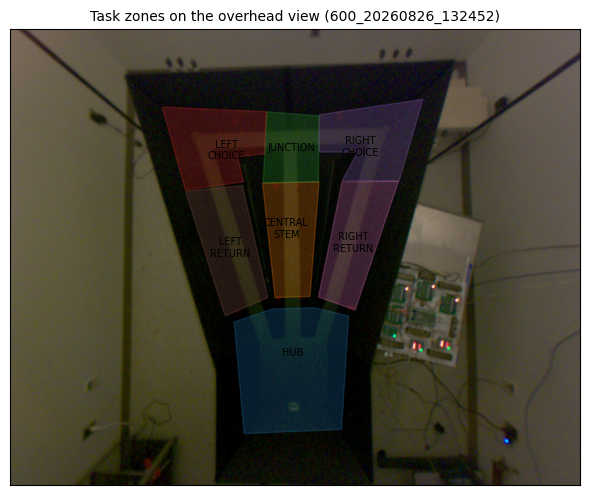

In [14]:
ref = high  # any block; its session supplies the background + zones
_, sc, zm, img = bundle_assets(ref)
W, H = _frame_dims(sc, img)

fig, ax = plt.subplots(figsize=(6, 5))
if img is not None:
    ax.imshow(img, cmap="gray", zorder=0)
else:
    ax.set_xlim(0, W)
    ax.set_ylim(H, 0)
cmap = plt.get_cmap("tab10")
for k, z in enumerate(zm.zones):
    xy = np.asarray(z.polygon, dtype=float) * [W, H]
    ax.add_patch(mpatches.Polygon(xy, closed=True, fill=True, alpha=0.25,
                                  color=cmap(k % 10), zorder=1))
    c = xy.mean(axis=0)
    ax.text(c[0], c[1], z.name.replace("_", "\n"), ha="center", va="center",
            fontsize=7, zorder=2)
ax.set_xticks([])
ax.set_yticks([])
ax.set_aspect("equal")
ax.set_title(f"Task zones on the overhead view ({ref.session_id})", fontsize=10)
fig.tight_layout()
out = OUTPUT_DIR / "zones_reference.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
print("saved", out.resolve())